In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

## Load Data & Cleaning

In [6]:
df = pd.read_csv("../data/data_gempa_10_tahun.csv")
df

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-04-07T13:40:15.182Z,-6.1919,103.7635,30.783,5.0,mb,106.0,64,1.989,0.64,...,2026-04-07T14:47:29.040Z,"186 km WSW of Bandar Lampung, Indonesia",earthquake,7.12,4.410,0.059,93.0,reviewed,us,us
1,2026-04-07T03:43:09.280Z,1.0699,126.2083,46.569,4.8,mb,53.0,82,5.993,0.78,...,2026-04-07T04:10:18.040Z,"126 km ESE of Bitung, Indonesia",earthquake,9.70,7.073,0.058,91.0,reviewed,us,us
2,2026-04-06T08:21:52.585Z,1.1734,126.4276,35.000,4.7,mb,68.0,91,5.918,0.41,...,2026-04-07T08:32:40.040Z,"114 km WNW of Ternate, Indonesia",earthquake,4.48,1.908,0.079,49.0,reviewed,us,us
3,2026-04-06T05:32:11.735Z,1.5073,126.4387,35.000,4.9,mb,61.0,93,5.591,0.53,...,2026-04-06T05:53:44.040Z,"131 km NW of Ternate, Indonesia",earthquake,6.99,1.828,0.067,70.0,reviewed,us,us
4,2026-04-06T01:56:46.796Z,1.4332,126.2604,35.000,4.8,mb,59.0,98,7.384,0.78,...,2026-04-06T02:44:20.040Z,"125 km E of Bitung, Indonesia",earthquake,11.16,1.916,0.061,83.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8706,2016-04-01T20:42:09.550Z,4.0341,128.2741,17.170,4.6,mb,NaN,44,3.365,0.82,...,2016-06-17T21:44:54.040Z,"256 km N of Tobelo, Indonesia",earthquake,7.30,4.600,0.069,62.0,reviewed,us,us
8707,2016-04-01T07:23:44.630Z,3.9260,128.2415,10.000,4.9,mb,NaN,96,3.252,1.04,...,2016-06-17T21:44:50.040Z,"244 km N of Tobelo, Indonesia",earthquake,7.10,1.900,0.067,71.0,reviewed,us,us
8708,2016-04-01T06:11:32.450Z,-3.5238,131.3260,34.490,4.6,mb,NaN,54,1.099,0.91,...,2016-06-17T21:44:50.040Z,"268 km E of Amahai, Indonesia",earthquake,6.40,5.400,0.086,40.0,reviewed,us,us
8709,2016-03-31T19:38:42.320Z,3.1211,96.2001,11.080,5.1,mb,NaN,30,2.222,0.80,...,2016-06-10T23:32:59.040Z,"73 km NNW of Sinabang, Indonesia",earthquake,6.90,3.200,0.053,115.0,reviewed,us,us


In [59]:
df.isnull().sum()

time               0
latitude           0
longitude          0
depth              0
mag                0
magType            0
nst                0
gap                0
dmin               0
rms                0
net                0
id                 0
updated            0
place              0
type               0
horizontalError    0
depthError         0
magError           0
magNst             0
status             0
locationSource     0
magSource          0
dtype: int64

In [7]:
df.describe()

,latitude,longitude,depth,mag,nst,gap,dmin,rms,horizontalError,depthError,magError,magNst
count,8711.000000,8711.000000,8711.000000,8711.000000,3354.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8666.000000,8666.000000
mean,-1.970819,121.091805,74.663656,4.792113,65.688432,77.402939,2.208450,0.798399,7.296279,4.769392,0.094806,44.150704
std,4.795859,11.137998,98.775513,0.359648,41.865304,37.091001,1.308037,0.225386,1.906707,2.694534,0.038619,35.414159
min,-10.661000,92.942100,3.604000,4.500000,9.000000,10.000000,0.008000,0.140000,1.800000,0.200000,0.027000,1.000000
25%,-6.573750,116.986550,10.000000,4.500000,37.000000,49.000000,1.377500,0.640000,6.200000,1.900000,0.069000,20.000000
50%,-1.567100,126.225100,42.070000,4.700000,55.000000,72.000000,2.017000,0.780000,7.200000,4.845000,0.087000,33.000000
75%,2.058700,128.159150,95.885500,4.900000,82.000000,100.000000,2.723000,0.940000,8.300000,6.900000,0.111000,57.000000
max,6.313500,138.680300,673.060000,7.600000,401.000000,267.000000,29.880000,1.640000,27.090000,26.300000,0.540000,338.000000


In [8]:
df["magNst"] = df["magNst"].fillna(df["magNst"].median())
df["magError"] = df["magError"].fillna(df["magError"].mean())
df["nst"] = df["nst"].fillna(df["nst"].median())


In [9]:
df

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-04-07T13:40:15.182Z,-6.1919,103.7635,30.783,5.0,mb,106.0,64,1.989,0.64,...,2026-04-07T14:47:29.040Z,"186 km WSW of Bandar Lampung, Indonesia",earthquake,7.12,4.410,0.059,93.0,reviewed,us,us
1,2026-04-07T03:43:09.280Z,1.0699,126.2083,46.569,4.8,mb,53.0,82,5.993,0.78,...,2026-04-07T04:10:18.040Z,"126 km ESE of Bitung, Indonesia",earthquake,9.70,7.073,0.058,91.0,reviewed,us,us
2,2026-04-06T08:21:52.585Z,1.1734,126.4276,35.000,4.7,mb,68.0,91,5.918,0.41,...,2026-04-07T08:32:40.040Z,"114 km WNW of Ternate, Indonesia",earthquake,4.48,1.908,0.079,49.0,reviewed,us,us
3,2026-04-06T05:32:11.735Z,1.5073,126.4387,35.000,4.9,mb,61.0,93,5.591,0.53,...,2026-04-06T05:53:44.040Z,"131 km NW of Ternate, Indonesia",earthquake,6.99,1.828,0.067,70.0,reviewed,us,us
4,2026-04-06T01:56:46.796Z,1.4332,126.2604,35.000,4.8,mb,59.0,98,7.384,0.78,...,2026-04-06T02:44:20.040Z,"125 km E of Bitung, Indonesia",earthquake,11.16,1.916,0.061,83.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8706,2016-04-01T20:42:09.550Z,4.0341,128.2741,17.170,4.6,mb,55.0,44,3.365,0.82,...,2016-06-17T21:44:54.040Z,"256 km N of Tobelo, Indonesia",earthquake,7.30,4.600,0.069,62.0,reviewed,us,us
8707,2016-04-01T07:23:44.630Z,3.9260,128.2415,10.000,4.9,mb,55.0,96,3.252,1.04,...,2016-06-17T21:44:50.040Z,"244 km N of Tobelo, Indonesia",earthquake,7.10,1.900,0.067,71.0,reviewed,us,us
8708,2016-04-01T06:11:32.450Z,-3.5238,131.3260,34.490,4.6,mb,55.0,54,1.099,0.91,...,2016-06-17T21:44:50.040Z,"268 km E of Amahai, Indonesia",earthquake,6.40,5.400,0.086,40.0,reviewed,us,us
8709,2016-03-31T19:38:42.320Z,3.1211,96.2001,11.080,5.1,mb,55.0,30,2.222,0.80,...,2016-06-10T23:32:59.040Z,"73 km NNW of Sinabang, Indonesia",earthquake,6.90,3.200,0.053,115.0,reviewed,us,us


In [10]:
df.describe()

,latitude,longitude,depth,mag,nst,gap,dmin,rms,horizontalError,depthError,magError,magNst
count,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000,8711.000000
mean,-1.970819,121.091805,74.663656,4.792113,59.115371,77.402939,2.208450,0.798399,7.296279,4.769392,0.094806,44.093101
std,4.795859,11.137998,98.775513,0.359648,26.491021,37.091001,1.308037,0.225386,1.906707,2.694534,0.038519,35.331602
min,-10.661000,92.942100,3.604000,4.500000,9.000000,10.000000,0.008000,0.140000,1.800000,0.200000,0.027000,1.000000
25%,-6.573750,116.986550,10.000000,4.500000,55.000000,49.000000,1.377500,0.640000,6.200000,1.900000,0.069000,20.000000
50%,-1.567100,126.225100,42.070000,4.700000,55.000000,72.000000,2.017000,0.780000,7.200000,4.845000,0.088000,33.000000
75%,2.058700,128.159150,95.885500,4.900000,55.000000,100.000000,2.723000,0.940000,8.300000,6.900000,0.110000,57.000000
max,6.313500,138.680300,673.060000,7.600000,401.000000,267.000000,29.880000,1.640000,27.090000,26.300000,0.540000,338.000000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8711 entries, 0 to 8710
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             8711 non-null   object 
 1   latitude         8711 non-null   float64
 2   longitude        8711 non-null   float64
 3   depth            8711 non-null   float64
 4   mag              8711 non-null   float64
 5   magType          8711 non-null   object 
 6   nst              8711 non-null   float64
 7   gap              8711 non-null   int64  
 8   dmin             8711 non-null   float64
 9   rms              8711 non-null   float64
 10  net              8711 non-null   object 
 11  id               8711 non-null   object 
 12  updated          8711 non-null   object 
 13  place            8711 non-null   object 
 14  type             8711 non-null   object 
 15  horizontalError  8711 non-null   float64
 16  depthError       8711 non-null   float64
 17  magError      

##  EDA

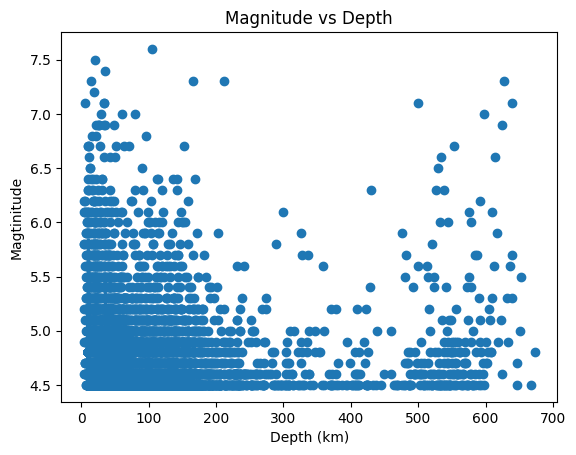

In [12]:
plt.scatter(df["depth"], df["mag"])
plt.xlabel("Depth (km)")
plt.ylabel("Magtinitude")
plt.title("Magnitude vs Depth")
plt.show()

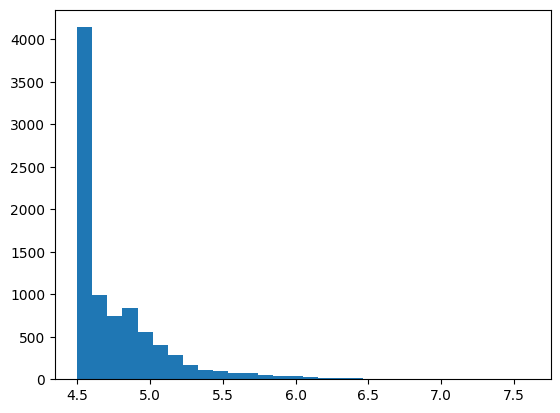

In [13]:
plt.hist(df["mag"], bins = 30)
plt.show()
        

In [17]:
df["lat"] = df["latitude"].round(1)
df["long"] = df["longitude"].round(1)
freq = df.groupby(["lat", "long"]).size()
freq

lat    long 
-10.7  115.9    1
       124.4    1
       124.5    1
       124.7    1
-10.6  108.0    1
               ..
 6.3   126.9    1
       127.0    1
       127.3    2
       127.5    1
       133.6    1
Length: 5067, dtype: int64

In [28]:
freq = df.groupby(["lat", "long"]).size().reset_index(name="count")

<Axes: xlabel='long', ylabel='lat'>

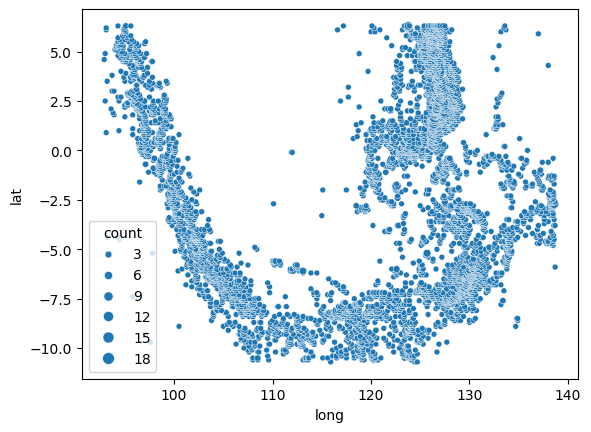

In [29]:
sns.scatterplot(data = freq, x =  "long", y = "lat", size = "count")

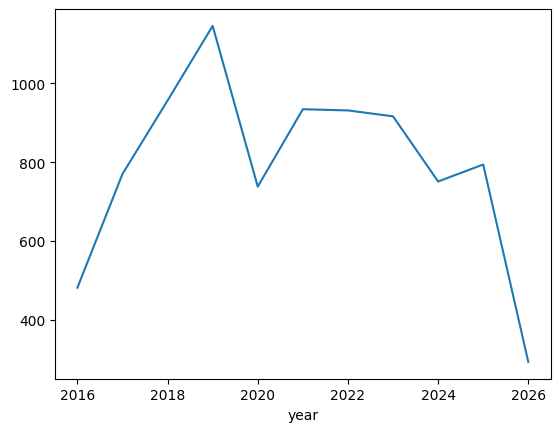

In [20]:
df["time"] = pd.to_datetime(df["time"])
df["year"] = df["time"].dt.year
freq_time = df.groupby("year").size()
sns.lineplot(x = freq_time.index, y = freq_time.values)
plt.show()

In [30]:
gempa_anomali = df[df["mag"] > 7.5]
gempa_anomali

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,horizontalError,depthError,magError,magNst,status,locationSource,magSource,lat,long,year
2738,2023-01-09 17:47:35.037000+00:00,-7.0586,130.009,104.95,7.6,mww,113.0,21,1.574,0.8,...,6.9,2.259,0.041,58.0,reviewed,us,us,-7.1,130.0,2023


<Axes: xlabel='long', ylabel='lat'>

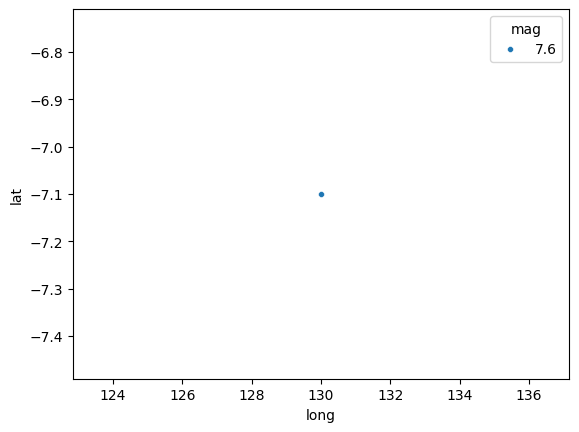

In [31]:
sns.scatterplot(data = gempa_anomali, x =  "long", y = "lat", size = "mag")

## Modeling
Random Forest Regressor for MAE, RMSE, R².

In [32]:
feature = ["latitude", "longitude", "depth", "nst", "magNst", "magError"]
X, y = df[feature], df["mag"]



In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [35]:
print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2  :", r2_score(y_test, pred))

MAE : 0.1137363740677002
RMSE: 0.17549190230307773
R2  : 0.7784647943260024


## EDA 
Kelas magnitudo & kedalaman, peta episenter, ringkasan per tahun, 10 wilayah teratas.

In [37]:

df["time"] = pd.to_datetime(df["time"])
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month

df["kelas_mag"] = pd.cut(df["mag"], bins=[0, 5, 5.5, 6, 7, 10], right=False, labels=["<5", "5-5.4", "5.5-5.9", "6-6.9", ">=7"])
df["kelas_depth"] = pd.cut(df["depth"], bins=[-1, 70, 300, 1000],labels=["Dangkal (<70 km)", "Menengah (70-300 km)", "Dalam (>300 km)"])
print(df["kelas_mag"].value_counts().sort_index())
print()
print(df["kelas_depth"].value_counts())

kelas_mag
<5         6716
5-5.4      1520
5.5-5.9     326
6-6.9       132
>=7          17
Name: count, dtype: int64

kelas_depth
Dangkal (<70 km)        5902
Menengah (70-300 km)    2497
Dalam (>300 km)          312
Name: count, dtype: int64


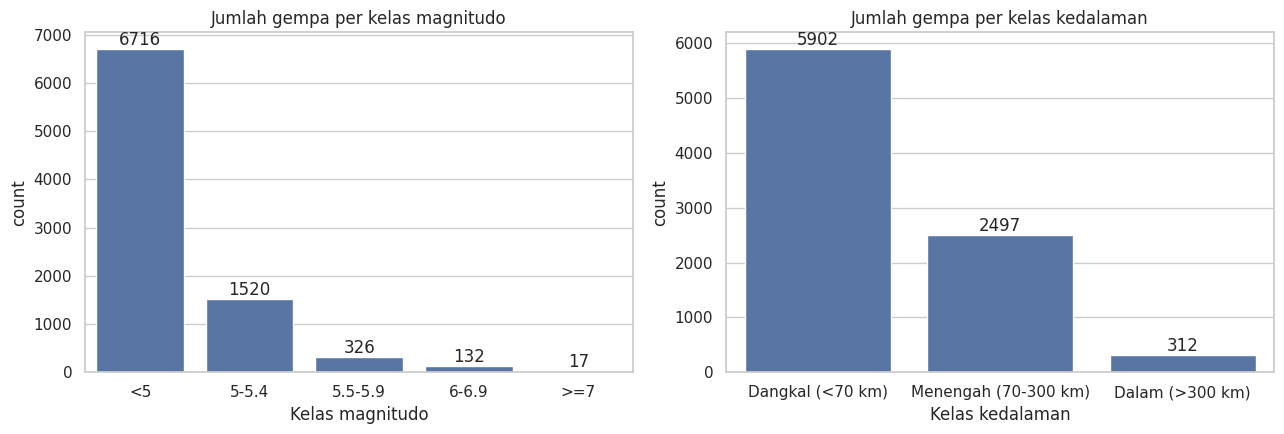

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="kelas_mag", order=["<5", "5-5.4", "5.5-5.9", "6-6.9", ">=7"], ax=axes[0])
axes[0].set_title("Jumlah gempa per kelas magnitudo")
axes[0].set_xlabel("Kelas magnitudo")
sns.countplot(data=df, x="kelas_depth", ax=axes[1])
axes[1].set_title("Jumlah gempa per kelas kedalaman")
axes[1].set_xlabel("Kelas kedalaman")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c)
plt.tight_layout()
plt.show()

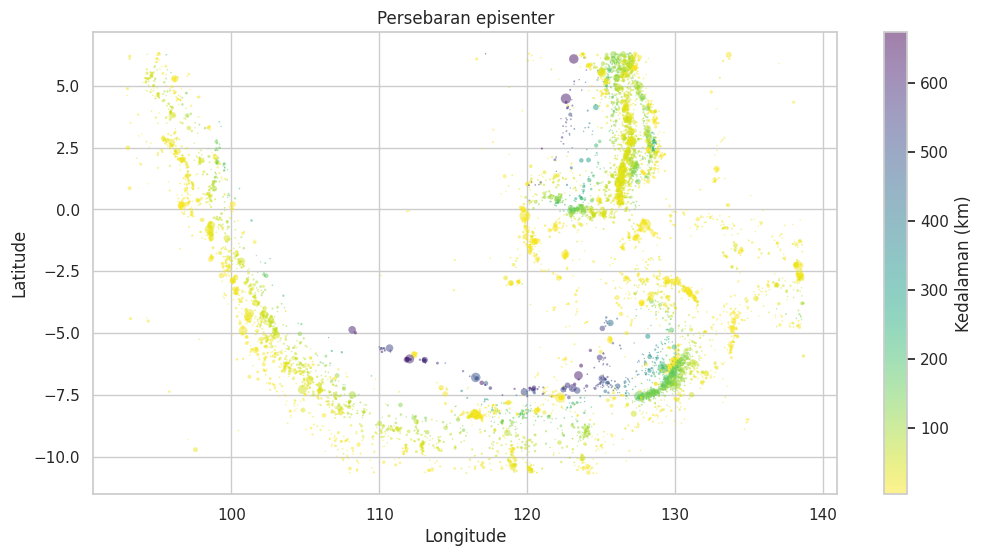

In [53]:
plt.figure(figsize=(12, 6))
sc = plt.scatter(df["longitude"], df["latitude"], c=df["depth"], s=(df["mag"] - 3.5) ** 3, cmap="viridis_r", alpha=0.5, edgecolor="none")
plt.colorbar(sc, label="Kedalaman (km)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Persebaran episenter")
plt.show()

In [50]:
summary = df.groupby("year").agg(jumlah=("mag", "size"), mag_rata2=("mag", "mean"), mag_maks=("mag", "max"), depth_rata2=("depth", "mean"), jumlah_M6_ke_atas=("mag", lambda s: (s >= 6).sum()),).round(2)
summary

,jumlah,mag_rata2,mag_maks,depth_rata2,jumlah_M6_ke_atas
year,,,,,
2016,482,4.82,6.7,88.64,10
2017,770,4.79,7.3,86.09,8
2018,956,4.81,7.5,70.80,15
2019,1145,4.81,7.3,68.15,20
2020,738,4.80,6.9,80.65,18
2021,934,4.78,7.3,75.46,18
2022,931,4.76,6.9,67.44,14
2023,916,4.80,7.6,70.51,22
2024,751,4.77,7.1,77.39,9


In [52]:
df["wilayah"] = df["place"].str.extract(r"of (.+?),")[0]
top_wilayah = df.groupby("wilayah").agg(jumlah=("mag", "size"), mag_rata2=("mag", "mean"), mag_maks=("mag", "max"), depth_rata2=("depth", "mean"),).round(2).sort_values("jumlah", ascending=False).head(10)
top_wilayah

,jumlah,mag_rata2,mag_maks,depth_rata2
wilayah,,,,
Tobelo,891,4.75,7.0,66.77
Ternate,542,4.80,7.4,44.39
Sarangani,398,4.77,6.7,69.05
Tual,395,4.77,6.7,59.52
Lospalos,378,4.73,7.3,145.18
Pondaguitan,356,4.76,7.0,71.15
Gorontalo,257,4.80,6.3,146.96
Amahai,200,4.78,5.9,47.27
Bengkulu,200,4.88,6.9,34.99
